# Анализ системы метрик приложения Procrastinate Pro+

Приложение Procrastinate Pro+ предоставляет пользователям доступ к развлекательному контенту: видео, подкастам и блогам. Пользователи могут выбрать несколько пакетов контента. Пакеты различаются по цене, объёму и содержанию.

К началу лета в приложении появился новый вид контента — спортивный. С его помощью менеджеры стремятся расширить аудиторию, добавив в неё пользователей, которые увлекаются спортом и здоровым образом жизни.

К запуску нового контента была скорректирована маркетинговая стратегия привлечения пользователей. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели).

После запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. Нужно разобраться, почему это происходит.

Задачи:
- Провести анализ юнит-экономики продукта в динамике за первые 28 дней;
- Разобраться в причинах стагнации выручки;
- Определить, какие источники привлечения приносят прибыль, а какие не выходят на уровень окупаемости;
- Дать рекомендации отделу маркетинга.


### Данные

Есть данные о посещениях приложения, покупках и расходах на маркетинг.
Данные собраны в трёх датасетах.

1. Датасет `ppro_visits.csv` — информация о посещениях приложения пользователями, которые зарегистрировались с 1 апреля 2024 года по 30 ноября 2024 года:
    - `user_id` — уникальный идентификатор пользователя;
    - `region` — страна пользователя;
    - `device` — категория устройства пользователя;
    - `channel` — идентификатор рекламного источника, из которого пришёл пользователь;
    - `session_start` — дата и время начала сессии;
    - `session_end` — дата и время окончания сессии.

2. Датасет `ppro_orders.csv` — информация о покупках:
    - `user_id` — уникальный идентификатор пользователя, который сделал покупку;
    - `event_dt` — дата и время покупки;
    - `revenue` — выручка.

3. Датасет `ppro_costs.csv` — информация о затратах на маркетинг:
    - `dt` — дата
    - `channel` — идентификатор рекламного источника;
    - `costs` — затраты на этот рекламный источник в этот день.
    
### План проекта
- Загрузить и предобработать данные.
- Подготовить данные для когортного анализа.
- Рассчитать и проанализировать метрики вовлечённости в продукт.
- Рассчитать и проанализировать финансовые метрики CAC, LTV и ROI за первые 28 дней с момента привлечения.
- Исследовать метрики в разрезе источника привлечения.
- Рассчитать период окупаемости маркетинговых вложений.
- Сформулировать выводы и рекомендации.


## Загрузка и предобработка данных

Загрузим данные и получим основную информацию о них. Проведём необходимую предобработку.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates

In [2]:
ppro_visits = 'https://code.s3.yandex.net/datasets/ppro_visits.csv'
ppro_orders = 'https://code.s3.yandex.net/datasets/ppro_orders.csv'
ppro_costs = 'https://code.s3.yandex.net/datasets/ppro_costs.csv'

visits = pd.read_csv(ppro_visits)
orders = pd.read_csv(ppro_orders)
costs = pd.read_csv(ppro_costs)

Таблица `visits`  

In [3]:
visits.head()

,user_id,region,device,channel,session_start,session_end
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00


In [4]:
visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user_id        161865 non-null  int64 
 1   region         161865 non-null  object
 2   device         161865 non-null  object
 3   channel        161865 non-null  object
 4   session_start  161865 non-null  object
 5   session_end    161865 non-null  object
dtypes: int64(1), object(5)
memory usage: 7.4+ MB


In [5]:
visits.sort_values('session_start')

,user_id,region,device,channel,session_start,session_end
297,767410614400,India,mobile,MediaTornado,2024-04-01 00:07:00,2024-04-01 01:07:00
286,641772204272,India,mobile,MediaTornado,2024-04-01 00:09:00,2024-04-01 00:22:00
214,934895210751,India,mobile,RocketSuperAds,2024-04-01 00:23:00,2024-04-01 00:49:00
92,226472994774,India,tv,FaceBoom,2024-04-01 00:31:00,2024-04-01 00:53:00
42,686701513307,India,desktop,MediaTornado,2024-04-01 00:35:00,2024-04-01 00:46:00
...,...,...,...,...,...,...
161570,248063126719,India,desktop,FaceBoom,2024-11-30 23:50:00,2024-12-01 00:03:00
161128,671589329611,India,mobile,TipTop,2024-11-30 23:53:00,2024-12-01 00:42:00
161526,510747868026,India,mobile,TipTop,2024-11-30 23:55:00,2024-12-01 00:36:00
161472,689124358734,India,mobile,FaceBoom,2024-11-30 23:57:00,2024-12-01 01:40:00


In [6]:
visits['region'].value_counts()

India    161865
Name: region, dtype: int64

In [7]:
visits['device'].value_counts()

mobile     95641
desktop    56609
tv          9615
Name: device, dtype: int64

In [8]:
visits['channel'].value_counts()

TipTop            59439
FaceBoom          36308
RocketSuperAds    36081
MediaTornado      30037
Name: channel, dtype: int64

Проверим, есть ли аномалии

In [9]:
mask = visits['session_end'] < visits['session_start']
visits[mask]

,user_id,region,device,channel,session_start,session_end


Приведём даты к более удобному формату

In [10]:
visits['session_start'] = pd.to_datetime(visits['session_start'])
visits['session_start'] = visits['session_start'].dt.floor('D')
visits['session_end'] = pd.to_datetime(visits['session_end'])
visits['session_end'] = visits['session_end'].dt.floor('D')

Дубликатов нет

In [11]:
visits.duplicated().sum()

0

Таблица `orders`  

In [12]:
orders.head()

,user_id,event_dt,revenue
0,771951256319,2024-04-01 05:56:26,2.99
1,829942381059,2024-04-01 14:55:02,2.99
2,727879856738,2024-04-01 22:15:09,14.99
3,481270888930,2024-04-01 06:05:14,2.99
4,844695029762,2024-04-01 01:19:52,2.99


In [13]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33893 entries, 0 to 33892
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   33893 non-null  int64  
 1   event_dt  33893 non-null  object 
 2   revenue   33893 non-null  float64
dtypes: float64(1), int64(1), object(1)
memory usage: 794.5+ KB


In [14]:
orders.duplicated().sum()

0

Проверим на аномалии

In [15]:
orders_err = (orders['revenue'] <= 0).sum()
orders

,user_id,event_dt,revenue
0,771951256319,2024-04-01 05:56:26,2.99
1,829942381059,2024-04-01 14:55:02,2.99
2,727879856738,2024-04-01 22:15:09,14.99
3,481270888930,2024-04-01 06:05:14,2.99
4,844695029762,2024-04-01 01:19:52,2.99
...,...,...,...
33888,397577560536,2024-11-30 16:47:45,2.99
33889,610390409217,2024-11-30 04:35:45,7.99
33890,74116424793,2024-11-30 04:16:46,2.99
33891,691138256176,2024-11-30 02:07:03,2.99


In [16]:
orders['revenue'].describe()

count    33893.000000
mean         3.439945
std          2.191299
min          2.990000
25%          2.990000
50%          2.990000
75%          2.990000
max         29.990000
Name: revenue, dtype: float64

In [17]:
orders['event_dt'] = pd.to_datetime(orders['event_dt'])

Таблица `costs`  

In [18]:
costs.head()

,dt,channel,costs
0,2024-04-01,FaceBoom,124.938874
1,2024-04-02,FaceBoom,88.147779
2,2024-04-03,FaceBoom,120.779457
3,2024-04-04,FaceBoom,98.981253
4,2024-04-05,FaceBoom,109.044760


In [19]:
costs.tail()

,dt,channel,costs
971,2024-11-26,TipTop,216.741490
972,2024-11-27,TipTop,263.071019
973,2024-11-28,TipTop,252.638555
974,2024-11-29,TipTop,261.943208
975,2024-11-30,TipTop,240.604295


In [20]:
costs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   dt       976 non-null    object 
 1   channel  976 non-null    object 
 2   costs    976 non-null    float64
dtypes: float64(1), object(2)
memory usage: 23.0+ KB


In [21]:
costs['channel'].value_counts()

FaceBoom          244
MediaTornado      244
TipTop            244
RocketSuperAds    244
Name: channel, dtype: int64

In [22]:
costs.duplicated().sum()

0

In [23]:
costs_err = (costs['costs'] <= 0).sum()
costs_err

0

In [24]:
costs['costs'].describe()

count    976.000000
mean      81.691910
std       70.237689
min        9.048984
25%       19.546203
50%       54.282076
75%      134.499067
max      316.923419
Name: costs, dtype: float64

In [25]:
costs['dt'] = pd.to_datetime(costs['dt'])

Всего для анализа представлены 3 таблицы, данные в них без пропусков, без дубликатов, выбросов и аномалий. Для удобства поменяли некоторые типы данных. Осталось 100% исходных данных.

## Подготовка данных к когортному анализу

Подготовим данные к когортному анализу с учётом того, что будем изучать окупаемость привлечения пользователей за первые 28 дней.

Для каждого пользователя найдём:
- дату первой сессии (дата привлечения пользователя, `first_dt`);
- канал привлечения (`first_channel`);
- стоимость привлечения пользователя (`cac`).

Результаты сохраним в новой таблице `profiles`.

In [26]:
profiles = (
    visits
    .sort_values('session_start')
    .groupby('user_id')
    .agg(first_dt = ('session_start', 'min'), first_channel = ('channel', 'first'))
    .reset_index()
)

profiles['cohort'] = profiles['first_dt'].dt.date

new_users_day = (
    profiles
    .groupby(['cohort', 'first_channel'])
    .size()
    .reset_index(name = 'new_users')
)

new_users_day.rename(columns = {'first_channel': 'channel', 'cohort': 'date'}, inplace = True)

costs['date'] = costs['dt'].dt.date

day_costs = (
    costs
    .groupby(['date', 'channel'])['costs']
    .sum()
    .reset_index(name = 'total_cost')
)

costs_users = day_costs.merge(
    new_users_day,
    on = ['date', 'channel'],
    how = 'left'
)

costs_users['new_users'] = costs_users['new_users'].fillna(0)
costs_users['cac'] = costs_users.apply(
    lambda row: row['total_cost'] / row['new_users'] if row['new_users'] > 0 else np.nan,
    axis = 1
)

profiles = profiles.merge(
    costs_users[['date', 'channel', 'cac']],
    left_on = ['cohort', 'first_channel'],
    right_on = ['date', 'channel'],
    how = 'left'
)

profiles = profiles.drop(columns = ['date', 'channel', 'cohort'])
profiles['cac'] = profiles['cac'].fillna(0)

profiles

,user_id,first_dt,first_channel,cac
0,26034876,2024-05-29,FaceBoom,0.953250
1,69890364,2024-06-28,RocketSuperAds,0.604917
2,75610104,2024-06-09,FaceBoom,1.196159
3,76692397,2024-10-21,FaceBoom,1.147967
4,80224421,2024-06-21,FaceBoom,1.208981
...,...,...,...,...
74851,999956504962,2024-07-04,MediaTornado,0.267129
74852,999959994517,2024-06-03,RocketSuperAds,0.829762
74853,999962248443,2024-10-27,RocketSuperAds,0.411066
74854,999970372492,2024-08-07,TipTop,2.103363


In [27]:
profiles.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 74856 entries, 0 to 74855
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        74856 non-null  int64         
 1   first_dt       74856 non-null  datetime64[ns]
 2   first_channel  74856 non-null  object        
 3   cac            74856 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ MB


Добавим к данным с событиями и покупками информацию о первом источнике привлечения и дату привлечения пользователя из созданной таблицы. После этого рассчитаем дневной лайфтайм для каждого события или покупки и добавим в таблицу в виде целого числа. В дальнейшем при проведении когортного анализа будем использовать информацию о первом источнике привлечения пользователя.

In [28]:
orders_2 = orders.merge(
    profiles[['user_id', 'first_dt', 'first_channel']],
    on = 'user_id',
    how = 'left'
)

orders_2['lifetime'] = orders_2['event_dt'] - orders_2['first_dt']
orders_2 = orders_2[orders_2['lifetime'] >= pd.Timedelta(0)]
orders_2['lifetime'] = orders_2['lifetime'].dt.days.astype(int)

orders_2

,user_id,event_dt,revenue,first_dt,first_channel,lifetime
0,771951256319,2024-04-01 05:56:26,2.99,2024-04-01,FaceBoom,0
1,829942381059,2024-04-01 14:55:02,2.99,2024-04-01,FaceBoom,0
2,727879856738,2024-04-01 22:15:09,14.99,2024-04-01,FaceBoom,0
3,481270888930,2024-04-01 06:05:14,2.99,2024-04-01,TipTop,0
4,844695029762,2024-04-01 01:19:52,2.99,2024-04-01,FaceBoom,0
...,...,...,...,...,...,...
33888,397577560536,2024-11-30 16:47:45,2.99,2024-11-30,RocketSuperAds,0
33889,610390409217,2024-11-30 04:35:45,7.99,2024-11-30,TipTop,0
33890,74116424793,2024-11-30 04:16:46,2.99,2024-11-30,FaceBoom,0
33891,691138256176,2024-11-30 02:07:03,2.99,2024-11-30,FaceBoom,0


In [29]:
orders_2.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 33893 entries, 0 to 33892
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        33893 non-null  int64         
 1   event_dt       33893 non-null  datetime64[ns]
 2   revenue        33893 non-null  float64       
 3   first_dt       33893 non-null  datetime64[ns]
 4   first_channel  33893 non-null  object        
 5   lifetime       33893 non-null  int64         
dtypes: datetime64[ns](2), float64(1), int64(2), object(1)
memory usage: 1.8+ MB


In [30]:
orders_2['lifetime'].value_counts().sort_index()

0      5207
1      2296
2      1523
3      1197
4      1021
       ... 
236       2
238       3
240       2
241       2
242       1
Name: lifetime, Length: 241, dtype: int64

In [31]:
orders_3 = orders_2[orders_2['lifetime'] > 0].head()
orders_3

,user_id,event_dt,revenue,first_dt,first_channel,lifetime
14,570274684514,2024-04-02 20:05:00,2.99,2024-04-01,FaceBoom,1
15,806481384856,2024-04-02 04:04:17,2.99,2024-04-01,MediaTornado,1
16,481270888930,2024-04-02 23:40:32,2.99,2024-04-01,TipTop,1
17,373037757367,2024-04-02 06:59:03,2.99,2024-04-01,FaceBoom,1
18,588009939701,2024-04-02 19:57:32,2.99,2024-04-01,TipTop,1


In [32]:
orders_4 = orders_2[orders_2['lifetime'] > 10].head()
orders_4

,user_id,event_dt,revenue,first_dt,first_channel,lifetime
478,550254063862,2024-04-12 15:55:37,2.99,2024-04-01,TipTop,11
534,481270888930,2024-04-13 08:01:36,29.99,2024-04-01,TipTop,12
535,787738461582,2024-04-13 06:11:10,2.99,2024-04-02,RocketSuperAds,11
536,516963432681,2024-04-13 00:33:25,2.99,2024-04-02,RocketSuperAds,11
537,637492425362,2024-04-13 16:12:39,2.99,2024-04-02,RocketSuperAds,11


In [33]:
orders_2['lifetime'].describe()

count    33893.000000
mean        33.178562
std         44.048899
min          0.000000
25%          2.000000
50%         14.000000
75%         48.000000
max        242.000000
Name: lifetime, dtype: float64

После подготовки получилась таблица `df_orders_2`, в которой содержится больше информации для анализа:добавлены столбцы `first_dt`, `first_channel` и `lifetime`.

## Анализ месячной динамики основных метрик продукта

Начнём анализ данных с изучения динамики активности пользователей и их вовлечённости в продукт. Рассчитаем по всем данным значения DAU, MAU и Stickiness и визуализируем их. Активными будем считать всех пользователей, которые взаимодействовали с приложением.

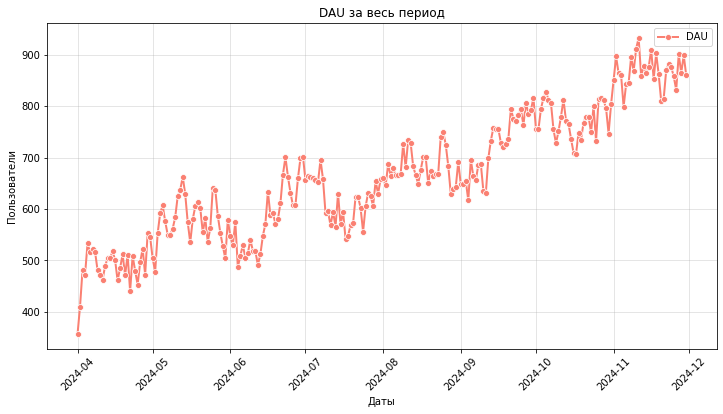

In [34]:
visits['session_start'] = pd.to_datetime(visits['session_start'])
visits['date'] = visits['session_start'].dt.normalize()

dau = (
    visits
    .sort_values('date')
    .groupby('date')['user_id']
    .nunique()
    .reset_index(name = 'dau')
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = dau, 
    x = 'date', 
    y = 'dau',
    label = 'DAU', 
    color = 'salmon', 
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Даты')
plt.ylabel('Пользователи')

plt.title('DAU за весь период')
plt.show()

Видно, как тренд идёт вверх, перепады цикличны. Нет резких обвалов и прерываний.

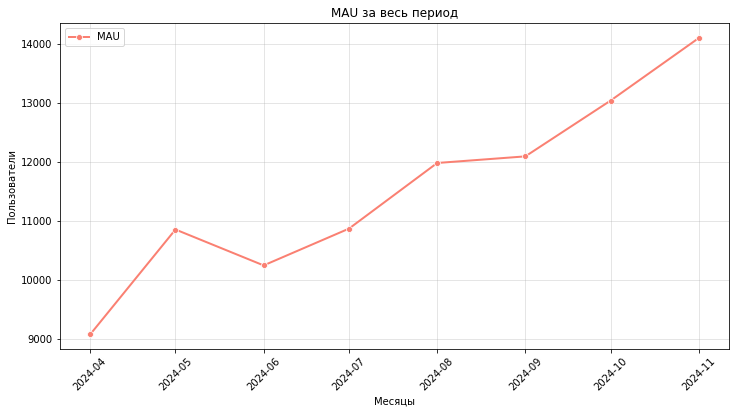

In [35]:
visits['date'] = pd.to_datetime(visits['date'])
visits['month'] = visits['date'].dt.to_period('M').astype(str)

mau = (
    visits
    .sort_values('month')
    .groupby('month')['user_id']
    .nunique()
    .reset_index(name = 'mau')
)

mau['date'] = pd.to_datetime(mau['month'])

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = mau, 
    x = 'date', 
    y = 'mau',
    label = 'MAU', 
    color = 'salmon', 
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Месяцы')
plt.ylabel('Пользователи')

plt.title('MAU за весь период')
plt.show()

Метрика растёт достаточно стабильно, но в июне виден спад, как раз в начале лета и изменении маркетинговой стратегии. После этого рост пошёл почти линейно. С августа по сентябрь произошла небольшая стагнация.

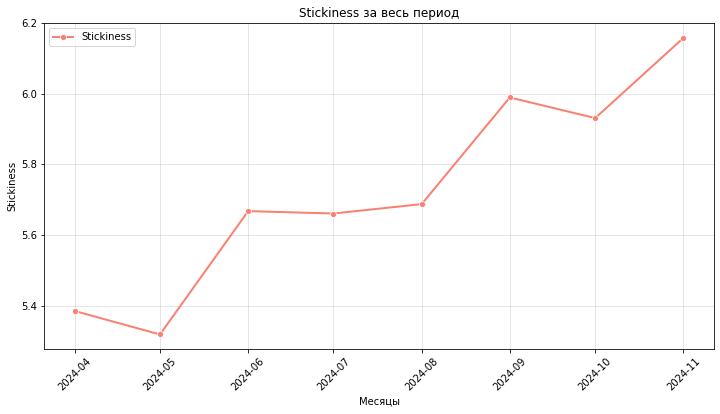

In [36]:
dau['month'] = dau['date'].dt.to_period('M').astype(str)
mau['month'] = mau['date'].dt.to_period('M').astype(str)

dau_month = (
    dau
    .sort_values('month')
    .groupby('month')['dau']
    .mean()
    .reset_index(name = 'dau_month')
)

mau_month = (
    mau
    .sort_values('month')
    .groupby('month')['mau']
    .mean()
    .reset_index(name = 'mau_month')
)

stickiness = dau_month.merge(mau_month, on = 'month')
stickiness['stickiness'] = (stickiness['dau_month'] / stickiness['mau_month']) * 100
stickiness['date'] = pd.to_datetime(stickiness['month'])

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = stickiness, 
    x = 'date', 
    y = 'stickiness',
    label = 'Stickiness', 
    color = 'salmon', 
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)

plt.xlabel('Месяцы')
plt.ylabel('Stickiness')

plt.title('Stickiness за весь период')
plt.show()

Stickiness за весь период не превышает 6,2%, тренд слабо идёт вверх с перепадами.

В разрезе каждого месяца привлечения новых пользователей рассчитаем:
- Среднюю стоимость привлечения пользователя (CAC).
- Значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

Здесь и далее при расчёте LTV и ROI учитываем всех привлечённых пользователей когорты.

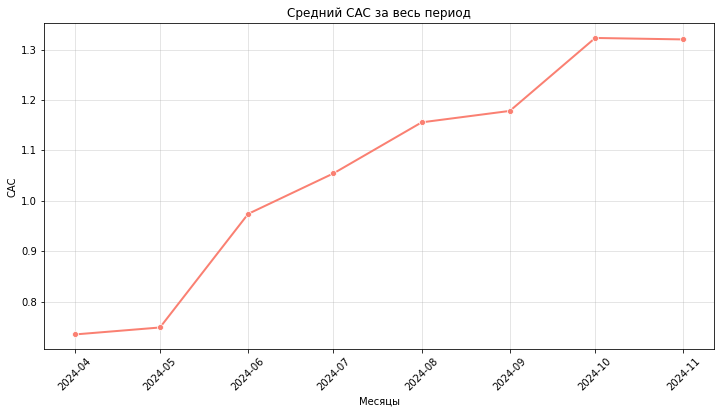

In [37]:
profiles_month = profiles.copy()
profiles_month['cohort_month'] = profiles_month['first_dt'].dt.to_period('M')

cac_month = profiles_month.groupby('cohort_month').agg(
    total_users = ('user_id', 'nunique'),
    avg_cac = ('cac', 'mean')
).reset_index()

cac_month['cohort_month'] = cac_month['cohort_month'].dt.to_timestamp()

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = cac_month, 
    x = 'cohort_month', 
    y = 'avg_cac', 
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)
plt.xlabel('Месяцы')
plt.ylabel('CAC')
plt.title('Средний CAC за весь период')
plt.show()

В июне произошёл резкий подъём метрики. Осенью началась череда стагнации и роста, в ноябре даже есть небольшой спад. Получается новая маркетинговая стратегия, которая началась летом, сильно тудорожила привлечение пользователей, и с каждым месяцем расходы растут.

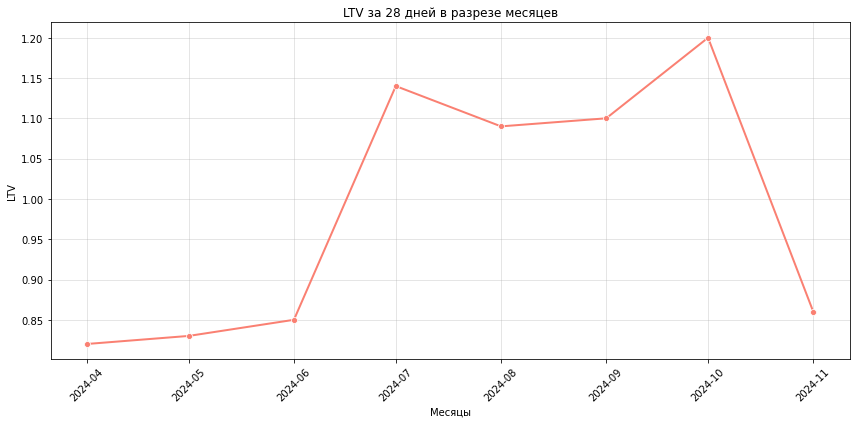

In [38]:
orders_28 = orders_2[orders_2['lifetime'] < 28].copy()

orders_28 = orders_28.merge(
    profiles[['user_id', 'first_dt']],
    on = 'user_id',
    how = 'left',
    suffixes = ('', '_profile')
)

orders_28['cohort_month'] = orders_28['first_dt_profile'].dt.to_period('M')

ltv_month = (
    orders_28
    .groupby('cohort_month')
    .agg(revenue_28 = ('revenue', 'sum'))
    .reset_index()
)

if str(ltv_month['cohort_month'].dtype).startswith('period'):
    ltv_month['cohort_month'] = ltv_month['cohort_month'].apply(lambda x: x.to_timestamp())
if not pd.api.types.is_datetime64_any_dtype(cac_month['cohort_month']):
    cac_month['cohort_month'] = pd.to_datetime(cac_month['cohort_month'])

ltv_month = ltv_month.merge(
    cac_month[['cohort_month', 'total_users']],
    on = 'cohort_month',
    how = 'left'
)

ltv_month['ltv_28'] = ltv_month['revenue_28'] / ltv_month['total_users']

ltv_month = ltv_month.sort_values('cohort_month')
ltv_month['ltv_28'] = ltv_month['ltv_28'].round(2)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = ltv_month, 
    x = 'cohort_month', 
    y = 'ltv_28', 
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)
plt.xlabel('Месяцы')
plt.ylabel('LTV')
plt.title('LTV за 28 дней в разрезе месяцев')
plt.tight_layout()
plt.show()

С момента изменения маркетинговой стратегии летом начался резкий рост LTV, новый контент стал приносить деньги. Ноябрьская когорта неполная.

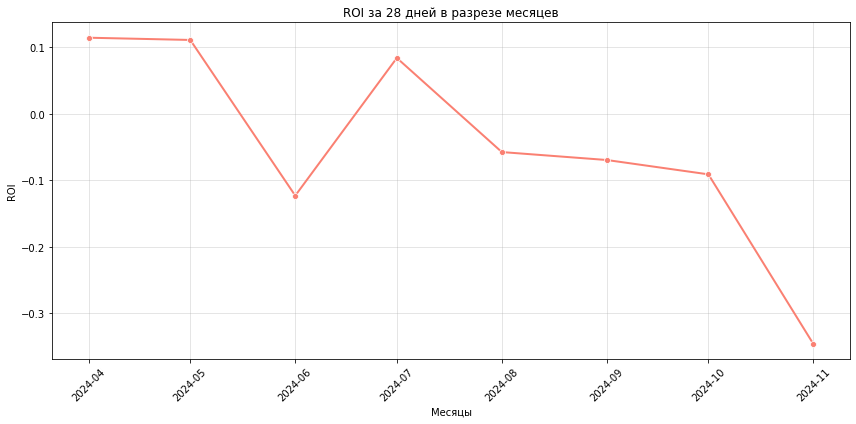

In [39]:
roi = ltv_month.merge(
    cac_month[['cohort_month', 'avg_cac']], 
    on = 'cohort_month',
    how = 'left'
)

roi['spend_cohort'] = roi['avg_cac'] * roi['total_users']
roi['roi_28'] = (roi['revenue_28'] - roi['spend_cohort']) / roi['spend_cohort']
roi = roi.sort_values('cohort_month')[['cohort_month', 'total_users', 'revenue_28', 'avg_cac', 'spend_cohort', 'roi_28']]

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = roi,
    x = 'cohort_month',
    y = 'roi_28',
    marker = 'o',
    linewidth = 2, 
    color = 'salmon'
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)
plt.xlabel('Месяцы')
plt.ylabel('ROI')
plt.title('ROI за 28 дней в разрезе месяцев')
plt.tight_layout()
plt.show()

К началу лета ROI резко упал, в июле снова удалось выйти в плюс, почле чего метрика вышла на новую норму ниже нуля с трендом на ухудшение. В июле резко вырос LTV, но расходы на привлечение с каждым месяцем растут. Новая маркетинговая стратегия пока выглядит неэффективно, а новый канал со спортом привёл только к краткосрочному улучшению.

## Анализ метрик в разрезе источника привлечения

Теперь необходимо разобраться, какие источники привлечения перспективны, а какие за 28 дней не окупились.

Определим самые популярные источники привлечения:
- Посчитаем общее число привлечённых пользователей для каждого источника.
- Визуализируем динамику набора новых пользователей по дням в каждом источнике.
- Рассчитаем и визуализируем динамику DAU, MAU и Stickiness по источникам привлечения.

In [40]:
profiles_channel = (
    profiles
    .groupby('first_channel')['user_id']
    .count()
    .reset_index()
)

profiles_channel.columns = ['source', 'total_users']

profiles_channel

,source,total_users
0,FaceBoom,28401
1,MediaTornado,14080
2,RocketSuperAds,14257
3,TipTop,18118


Самый популярный источник - `FaceBoom`.

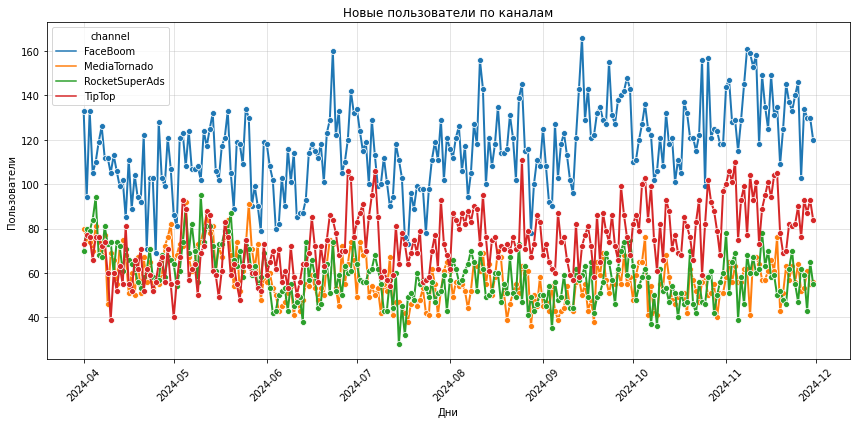

In [41]:
daily_users = (
    profiles
    .groupby(['first_dt', 'first_channel'])['user_id']
    .count()
    .reset_index(name = 'new_users')
)

daily_users.rename(columns = {'first_channel': 'channel'}, inplace = True)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = daily_users,
    x = 'first_dt',
    y = 'new_users',
    hue = 'channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)
plt.xlabel('Дни')
plt.ylabel('Пользователи')
plt.title('Новые пользователи по каналам')
plt.tight_layout()
plt.show()

Количество новых пользователей из каналов `RocketSuperAds` и `MediaTornado` скатываются с начала лета, посмотрим по неделям.

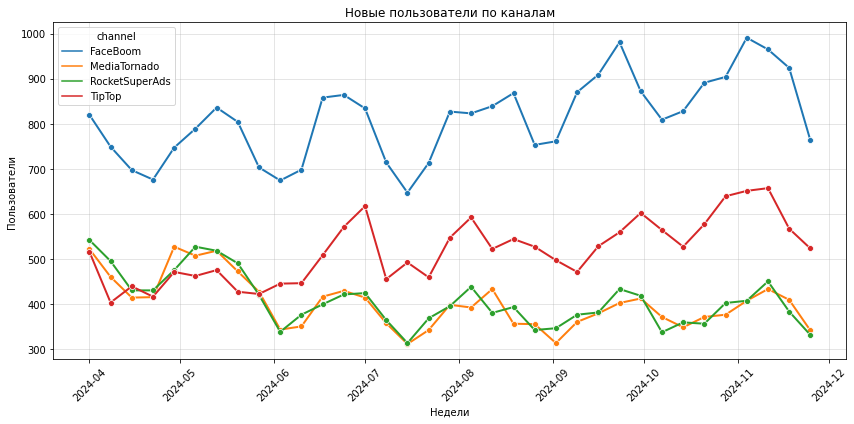

In [42]:
profiles['week'] = profiles['first_dt'].dt.to_period('W').dt.start_time

users_week = (
    profiles
    .groupby(['week', 'first_channel'])['user_id']
    .count()
    .reset_index(name = 'new_users')
)

users_week.rename(columns = {'first_channel': 'channel'}, inplace = True)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = users_week,
    x = 'week',
    y = 'new_users',
    hue = 'channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)
plt.xlabel('Месяцы')
plt.ylabel('Пользователи')
plt.title('Новые пользователи по каналам')
plt.tight_layout()
plt.show()

В июне просело всё, но `FaceBoom` и `TipTop` со временем начали расти и превысили показатели до изменения маркетинговой стратегией, продолжили скачкообразный рост.

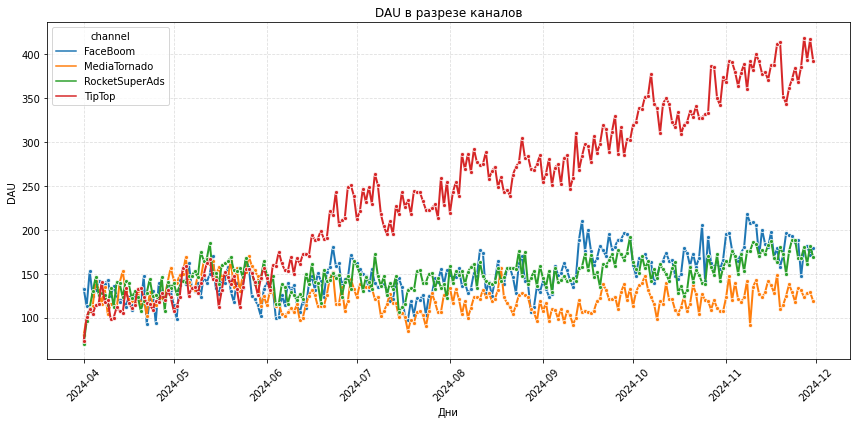

In [43]:
dau_visits = visits.copy()

dau_visits['date'] = pd.to_datetime(dau_visits['session_start']).dt.date

dau_channel = (
    dau_visits
    .groupby(['date', 'channel'])['user_id']
    .nunique() 
    .reset_index(name = 'dau')
)

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = dau_channel,
    x = 'date',
    y = 'dau',
    hue = 'channel',
    marker = 'o',
    linewidth = 2,
    markersize = 4
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45)
plt.xlabel('Дни')
plt.ylabel('DAU')
plt.title('DAU в разрезе каналов')
plt.tight_layout()
plt.show()

Самый лучший канал - `Tip Top`, он вышел на стабильный положительный тренд с началом лета. Другие показывают слабый рост после июня.

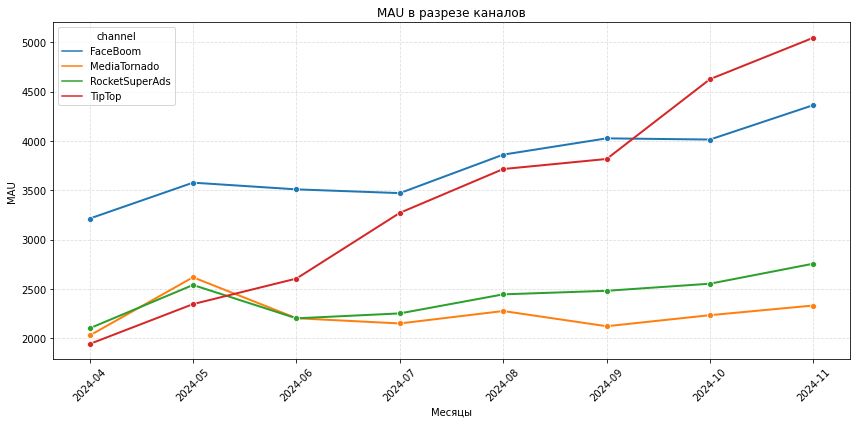

In [44]:
mau_visits = visits.copy()

mau_visits['month_period'] = pd.to_datetime(mau_visits['session_start']).dt.to_period('M')

mau_channel = (
    mau_visits
    .groupby(['month_period', 'channel'])['user_id']
    .nunique()
    .reset_index(name = 'mau')
)

mau_channel['month'] = mau_channel['month_period'].astype(str)
mau_channel = mau_channel.dropna(subset = ['channel'])
mau_channel = mau_channel.sort_values('month_period')

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = mau_channel,
    x = 'month',
    y = 'mau',
    hue = 'channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45)
plt.xlabel('Месяцы')
plt.ylabel('MAU')
plt.title('MAU в разрезе каналов')
plt.tight_layout()
plt.show()

Все показывают рост с началом лета, лучше всего `Tip Top`.

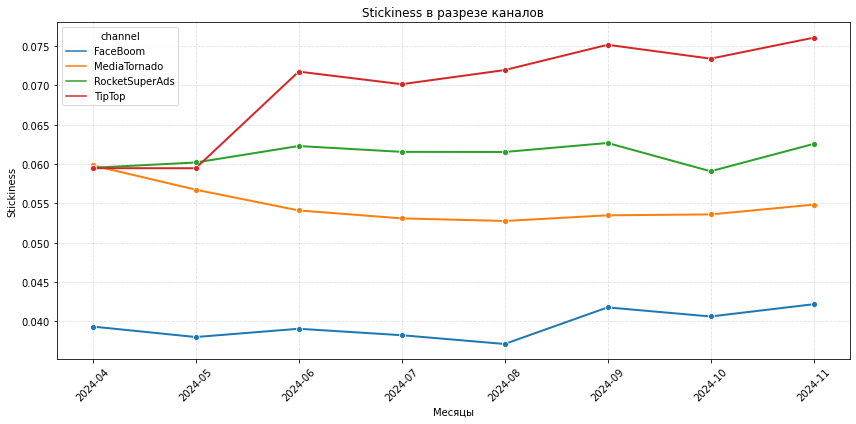

In [45]:
visits_all = visits.copy()
visits_all['date'] = pd.to_datetime(visits_all['session_start']).dt.date
visits_all['month'] = pd.to_datetime(visits_all['session_start']).dt.to_period('M')

mau_channel = (
    visits_all
    .groupby(['month', 'channel'])['user_id']
    .nunique()
    .reset_index(name = 'mau')
)

dau_channel_day = (
    visits_all
    .groupby(['date', 'month', 'channel'])['user_id'] 
    .nunique()
    .reset_index(name = 'dau')
)

dau_channel_month = (
    dau_channel_day
    .groupby(['month', 'channel'])['dau']
    .mean()
    .reset_index(name = 'avg_dau')
)

stickiness = mau_channel.merge(dau_channel_month, on = ['month', 'channel'], how = 'inner')
stickiness['stickiness'] = stickiness['avg_dau'] / stickiness['mau']
stickiness['month_str'] = stickiness['month'].astype(str)
stickiness = stickiness.sort_values(['channel', 'month'])

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = stickiness,
    x = 'month_str',
    y = 'stickiness',
    hue = 'channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45)
plt.xlabel('Месяцы')
plt.ylabel('Stickiness')
plt.title('Stickiness в разрезе каналов')
plt.tight_layout()
plt.show()

Каналы привлечения среагировали на изменение маркетинковой стратегии не сильно, но канал `TipTop` сильно вырос в показателях, он приводит много людей, котогрые дольше остаются на платформе.

Изучим динамику изменения метрик на 28-й день в разрезе источника. Проведём анализ с выделением недельных когорт по дате привлечения. Рассчитаем и визуализируем:
- Скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).
- Конверсию в покупку.

Недельную динамику затрат на маркетинг по каждому источнику привлечения.
Динамику среднего CAC, значений LTV и ROI.

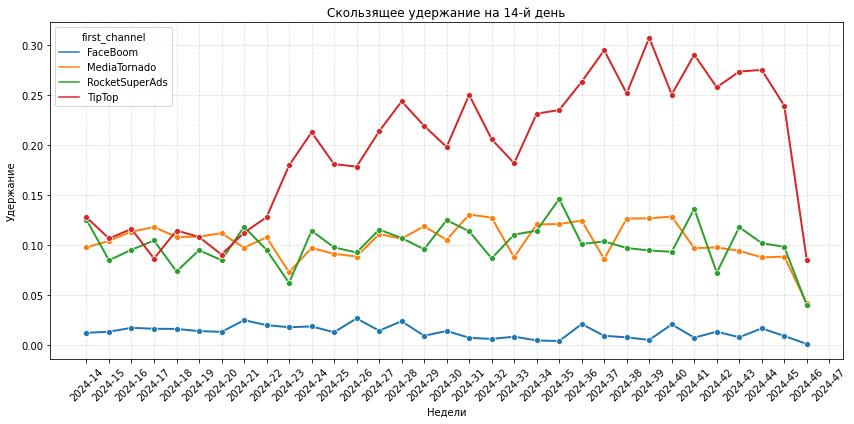

In [46]:
visits_cohort = visits.merge(profiles[['user_id', 'first_dt', 'first_channel']], on = 'user_id', how = 'inner')
visits_cohort['session_start'] = pd.to_datetime(visits_cohort['session_start'])
visits_cohort['first_dt'] = pd.to_datetime(visits_cohort['first_dt'])

visits_cohort['age_days'] = (visits_cohort['session_start'] - visits_cohort['first_dt']).dt.days
visits_cohort = visits_cohort[visits_cohort['age_days'] <= 28]
visits_cohort['cohort_week'] = visits_cohort['first_dt'].dt.isocalendar().year.astype(str) + '-' + visits_cohort['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)

cohort_size = (
    visits_cohort
    .groupby(['cohort_week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name = 'total_users')
)

retained_users = (
    visits_cohort
    .query('age_days >= 14 and age_days <= 28')
    .groupby(['cohort_week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name = 'retained_users')
)

retention_14_28 = cohort_size.merge(retained_users, on = ['cohort_week', 'first_channel'], how = 'left')
retention_14_28['retention_14_28'] = retention_14_28['retained_users'] / retention_14_28['total_users']

plt.figure(figsize = (12, 6))

sns.lineplot(
    data = retention_14_28,
    x = 'cohort_week',
    y = 'retention_14_28',
    hue = 'first_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45)
plt.xlabel('Недели')
plt.ylabel('Удержание')
plt.title('Скользящее удержание на 14‑й день')
plt.tight_layout()
plt.show()

Канал `FaceBoom` почти не удерживает пользователей.

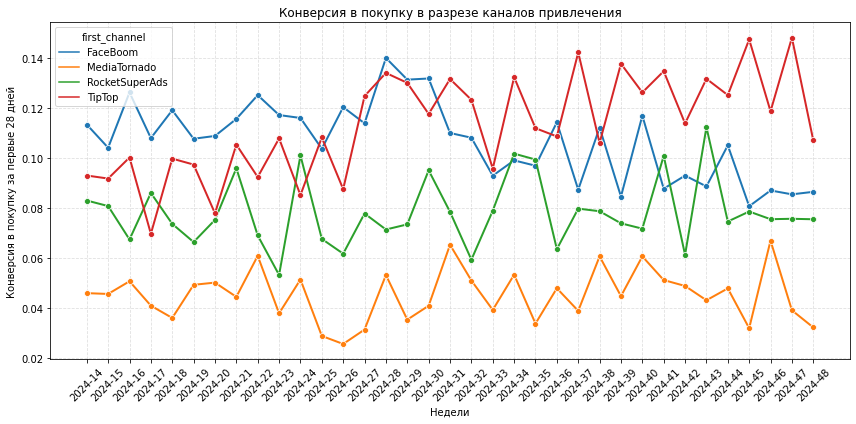

In [47]:
visits_cohort = visits.merge(profiles[['user_id', 'first_dt', 'first_channel']], on = 'user_id', how = 'inner')

visits_cohort['session_start'] = pd.to_datetime(visits_cohort['session_start'])
visits_cohort['first_dt'] = pd.to_datetime(visits_cohort['first_dt'])

visits_cohort['age_days'] = (visits_cohort['session_start'] - visits_cohort['first_dt']).dt.days
visits_cohort = visits_cohort[visits_cohort['age_days'] <= 28]

visits_cohort['cohort_week'] = (
    visits_cohort['first_dt'].dt.isocalendar().year.astype(str) + '-' + 
    visits_cohort['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

orders_with_cohort = orders.merge(profiles[['user_id', 'first_dt', 'first_channel']], on = 'user_id', how = 'inner')

orders_with_cohort['event_dt'] = pd.to_datetime(orders_with_cohort['event_dt'])
orders_with_cohort['first_dt'] = pd.to_datetime(orders_with_cohort['first_dt'])

orders_with_cohort['age_days'] = (orders_with_cohort['event_dt'] - orders_with_cohort['first_dt']).dt.days
orders_28 = orders_with_cohort[orders_with_cohort['age_days'] <= 28].copy()

orders_28['cohort_week'] = (
    orders_28['first_dt'].dt.isocalendar().year.astype(str) + '-' + 
    orders_28['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

cohort_size = (
    visits_cohort
    .groupby(['cohort_week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name = 'total_users')
)

purchasers_28 = (
    orders_28
    .groupby(['cohort_week', 'first_channel'])['user_id']
    .nunique()
    .reset_index(name = 'purchasers_count')
)

conversion_28 = cohort_size.merge(purchasers_28, on = ['cohort_week', 'first_channel'], how = 'left')
conversion_28['conversion_28d'] = conversion_28['purchasers_count'] / conversion_28['total_users']
conversion_28['conversion_28d'] = conversion_28['conversion_28d'].fillna(0)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data = conversion_28,
    x = 'cohort_week',
    y = 'conversion_28d',
    hue = 'first_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4, linestyle = '--')
plt.xticks(rotation = 45)
plt.xlabel('Недели')
plt.ylabel('Конверсия в покупку за первые 28 дней')
plt.title('Конверсия в покупку в разрезе каналов привлечения')
plt.tight_layout()
plt.show()

У канала `TipTop` конверсия в покупку тоже лучше всего выросла после мая, а у `Face Boom` скатилась.

In [48]:
profiles['first_dt'] = pd.to_datetime(profiles['first_dt'])

profiles['cohort_week'] = (
    profiles['first_dt'].dt.isocalendar().year.astype(str) + '-' +
    profiles['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

orders_28 = orders_2[
    orders_2['event_dt'] <= (orders_2['first_dt'] + pd.Timedelta(days = 28))
].copy()

orders_28['cohort_week'] = (
    orders_28['first_dt'].dt.isocalendar().year.astype(str) + '-' +
    orders_28['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

cac_agg = (
    profiles
    .groupby(['cohort_week', 'first_channel'])
    .agg(
        total_users = ('user_id', 'nunique'),
        total_cac = ('cac', 'sum'),
        avg_cac = ('cac', 'mean')
    )
    .reset_index()
)

revenue_agg = (
    orders_28
    .groupby(['cohort_week', 'first_channel'])['revenue']
    .sum()
    .reset_index(name = 'total_revenue')
)

orders_28['days_since_first'] = (orders_28['event_dt'] - orders_28['first_dt']).dt.days

retention_window = orders_28[
    (orders_28['days_since_first'] >= 14) & 
    (orders_28['days_since_first'] <= 28)
].copy()

user_retention = (
    retention_window
    .groupby(['user_id', 'cohort_week', 'first_channel'])
    .size()
    .reset_index(name = 'order_window')
)
user_retention['order_window'] = 1

all_users = profiles[['user_id', 'cohort_week', 'first_channel']].drop_duplicates()

users_with_retention = all_users.merge(user_retention, on = ['user_id', 'cohort_week', 'first_channel'], how = 'left')


retention_agg = (
    users_with_retention
    .groupby(['cohort_week', 'first_channel'])['order_window']
    .mean()
    .reset_index(name = 'retention_14_28')
)

metrics_data = (
    cac_agg
    .merge(revenue_agg, on = ['cohort_week', 'first_channel'], how = 'left')
    .merge(retention_agg, on = ['cohort_week', 'first_channel'], how = 'left')
)

metrics_data['ltv'] = metrics_data['total_revenue'] / metrics_data['total_users']
metrics_data['roi'] = (metrics_data['total_revenue'] - metrics_data['total_cac']) / metrics_data['total_cac']

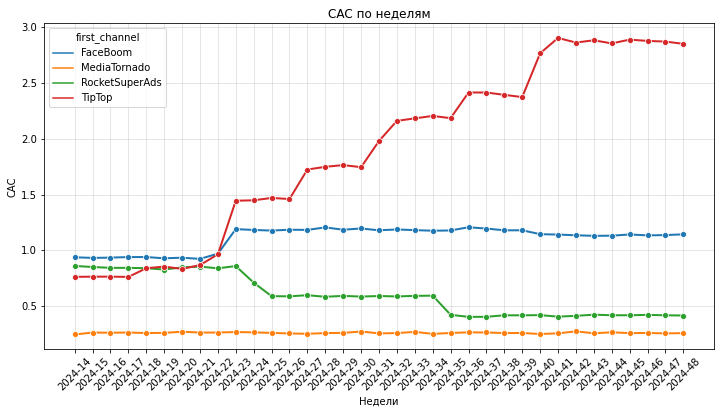

In [49]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = cac_agg, 
    x = 'cohort_week', 
    y = 'avg_cac', 
    hue = 'first_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)
plt.xlabel('Недели')
plt.ylabel('CAC')
plt.title('CAC по неделям')
plt.show()

Начиная с июня суммарные маркетинговые затраты для привлечения пользователей из канала `Tip Top` выросли примерно в три раза относительно первой половины года, это накладывается на предыдущие графики с резким скачком привлен=чения числа пользователей из этого источника. Канал `Media Tornado` не изменнился, оставшиеся скорректировались и вышли на свои новые нормы.

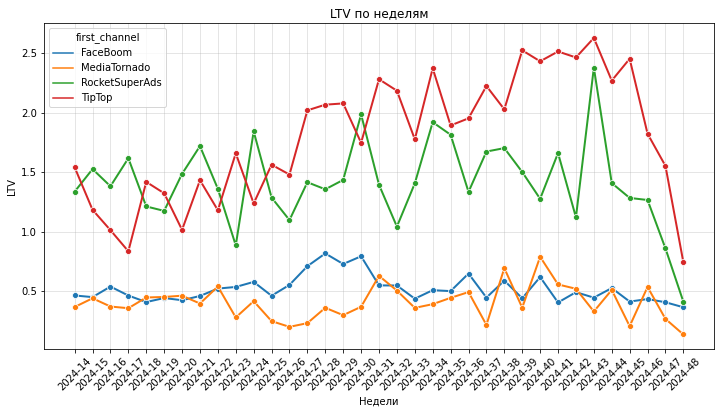

In [50]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data = metrics_data, 
    x = 'cohort_week', 
    y = 'ltv', 
    hue = 'first_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = .4)
plt.xticks(rotation = 45)
plt.xlabel('Недели')
plt.ylabel('LTV')
plt.title('LTV по неделям')
plt.show()

Больше всего денег приносят `Rocket Super Ads` и `Tip Top`, у них динамика положительная. `Face Boom` после резкого всплеска летом скатился ближе к 0. `Media Tornado` Тоже просел.

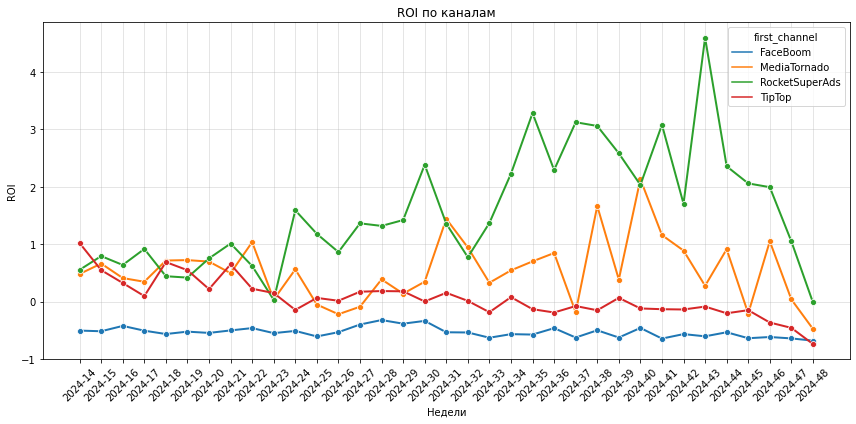

In [51]:
plt.figure(figsize = (12, 6))

sns.lineplot(
    data=metrics_data, 
    x = 'cohort_week', 
    y = 'roi', 
    hue = 'first_channel',
    marker = 'o',
    linewidth = 2
)

plt.grid(alpha = 0.4)
plt.xticks(rotation = 45)
plt.xlabel('Недели')
plt.ylabel('ROI')
plt.title('ROI по каналам')
plt.tight_layout()
plt.show()

Получается как раз канал `Face Boom`, который привлекает больше всего пользователей - за 28 дней не окупается совсем и не удерживает людей. Летом, после небольших колебаний, перестал окупаться и `Tip Top`, хотя денег в него вливается больше всего. На грани находится `Media Tornado`, у этого канала очень сильные перепады. С началом лета активно и, с перепадами, расти канал `Rocket Super Ads`, хотя именно после мая затраты на привлечение из этого канала снизились, возможно новая маркетинговая стратегия повлияла. Удержание и конверсия в покупку у этого источника средняя, на уровне `Media Tornado` (может стоит обратить на этот канал больше внимания и увеличить финансирование). Если новый спортивный контент привлекает пользователей через канал `Rocket Super Ads`, то это удачное решение, и можно выяснить, какая корреляция есть между темой контента и контекстом рекламы.

## Анализ периода окупаемости маркетинговых вложений

Для источников `Face Boom` и `Tip Top`, которые к 28-му дню не выходят на уровень окупаемости, рассчитаем и визуализируем в виде тепловой карты значения ROI за больший период.
Разделиим данные на недельные когорты по дате привлечения, в качестве интервала наблюдений используем недели.

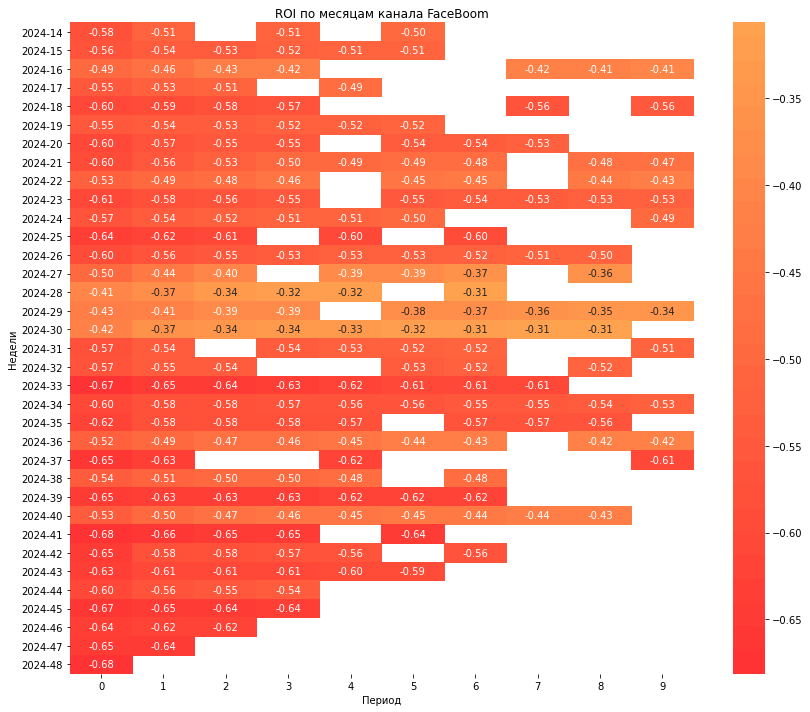

In [52]:
profiles['first_dt'] = pd.to_datetime(profiles['first_dt'])
orders_2['event_dt'] = pd.to_datetime(orders_2['event_dt'])

profiles['cohort_week'] = (
    profiles['first_dt'].dt.isocalendar().year.astype(str) + '-' +
    profiles['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

orders_3 = orders_2.copy()
orders_3['cohort_week'] = (
    orders_3['first_dt'].dt.isocalendar().year.astype(str) + '-' +
    orders_3['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

orders_70 = orders_3[(orders_3['event_dt'] - orders_3['first_dt']) <= pd.Timedelta(days = 70)].copy()

orders_70['days_since_first'] = (orders_70['event_dt'] - orders_70['first_dt']).dt.days
orders_70['obs_week'] = (orders_70['days_since_first'] // 7).clip(upper = 9)

revenue_week = (
    orders_70
    .groupby(['cohort_week', 'first_channel', 'obs_week'])['revenue']
    .sum()
    .reset_index()
)

revenue_week = revenue_week.sort_values(['cohort_week', 'first_channel', 'obs_week'])
revenue_week['cum_revenue'] = revenue_week.groupby(['cohort_week', 'first_channel'])['revenue'].cumsum()

cac_agg = (
    profiles
    .groupby(['cohort_week', 'first_channel'])
    .agg(total_users = ('user_id', 'nunique'), total_cac = ('cac', 'sum'))
    .reset_index()
)

roi_data = revenue_week.merge(
    cac_agg[['cohort_week', 'first_channel', 'total_cac']],
    on = ['cohort_week', 'first_channel'],
    how = 'left'
)

roi_data['roi'] = np.where(
    roi_data['total_cac'] > 0,
    (roi_data['cum_revenue'] - roi_data['total_cac']) / roi_data['total_cac'],
    np.nan
)

roi_tiptop = roi_data.query('first_channel == "FaceBoom"')

pivot_roi = roi_tiptop.pivot_table(
    index = 'cohort_week',
    columns = 'obs_week',
    values = 'roi',
    aggfunc = 'first'
)

pivot_roi = pivot_roi.reindex(sorted(pivot_roi.index))
pivot_roi.columns = pivot_roi.columns.astype(int)

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N = 100)

plt.figure(figsize = (12, 10))

ax = sns.heatmap(
    pivot_roi,
    cmap = cmap,
    center = 0,
    annot = True,
    fmt = '.2f',
    linewidths = 0
)

plt.title('ROI по месяцам канала FaceBoom')
plt.xlabel('Период')
plt.ylabel('Недели')
plt.tight_layout()
plt.show()

Источник `FaceBoom` абсолютно убыточен даже после многих недель.

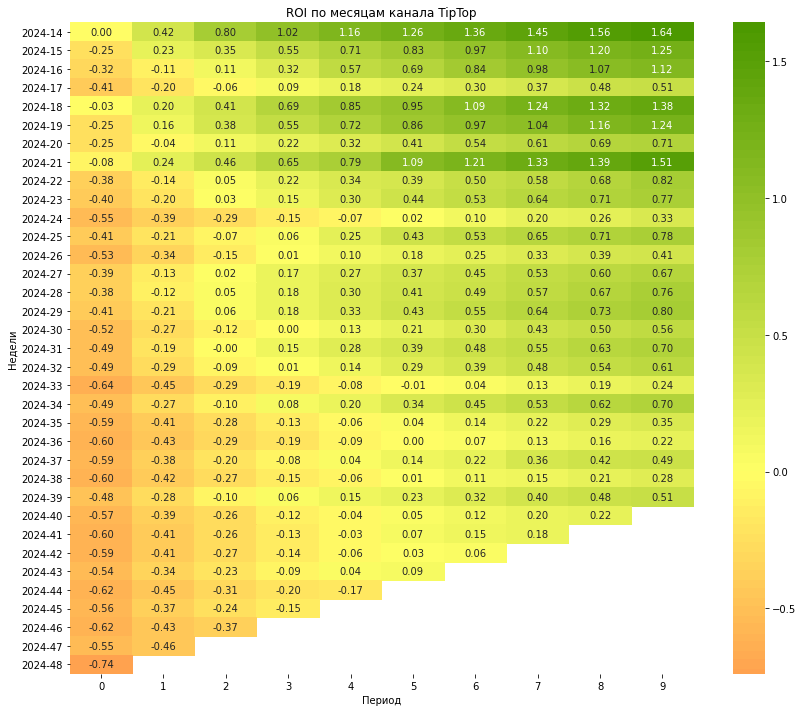

In [53]:
profiles['first_dt'] = pd.to_datetime(profiles['first_dt'])
orders_2['event_dt'] = pd.to_datetime(orders_2['event_dt'])

profiles['cohort_week'] = (
    profiles['first_dt'].dt.isocalendar().year.astype(str) + '-' +
    profiles['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

orders_3 = orders_2.copy()
orders_3['cohort_week'] = (
    orders_3['first_dt'].dt.isocalendar().year.astype(str) + '-' +
    orders_3['first_dt'].dt.isocalendar().week.astype(str).str.zfill(2)
)

orders_70 = orders_3[(orders_3['event_dt'] - orders_3['first_dt']) <= pd.Timedelta(days = 70)].copy()

orders_70['days_since_first'] = (orders_70['event_dt'] - orders_70['first_dt']).dt.days
orders_70['obs_week'] = (orders_70['days_since_first'] // 7).clip(upper = 9)

revenue_week = (
    orders_70
    .groupby(['cohort_week', 'first_channel', 'obs_week'])['revenue']
    .sum()
    .reset_index()
)

revenue_week = revenue_week.sort_values(['cohort_week', 'first_channel', 'obs_week'])
revenue_week['cum_revenue'] = revenue_week.groupby(['cohort_week', 'first_channel'])['revenue'].cumsum()

cac_agg = (
    profiles
    .groupby(['cohort_week', 'first_channel'])
    .agg(total_users = ('user_id', 'nunique'), total_cac = ('cac', 'sum'))
    .reset_index()
)

roi_data = revenue_week.merge(
    cac_agg[['cohort_week', 'first_channel', 'total_cac']],
    on = ['cohort_week', 'first_channel'],
    how = 'left'
)

roi_data['roi'] = np.where(
    roi_data['total_cac'] > 0,
    (roi_data['cum_revenue'] - roi_data['total_cac']) / roi_data['total_cac'],
    np.nan
)

roi_tiptop = roi_data.query('first_channel == "TipTop"')

pivot_roi = roi_tiptop.pivot_table(
    index = 'cohort_week',
    columns = 'obs_week',
    values = 'roi',
    aggfunc = 'first'
)

pivot_roi = pivot_roi.reindex(sorted(pivot_roi.index))
pivot_roi.columns = pivot_roi.columns.astype(int)

cmap = mcolors.LinearSegmentedColormap.from_list('green_red', ['#FF3333', '#FFFF66', '#4C9900'], N = 100)

plt.figure(figsize = (12, 10))

ax = sns.heatmap(
    pivot_roi,
    cmap = cmap,
    center = 0,
    annot = True,
    fmt = '.2f',
    linewidths = 0
)

plt.title('ROI по месяцам канала TipTop')
plt.xlabel('Период')
plt.ylabel('Недели')
plt.tight_layout()
plt.show()

Канал привлечения `TipTop` хоть и окупается в среднем к пятой неделе, тенденция у него негативная, постепенно показатели снижаются, и этот источник окупается всё позднее.

## Выводы и рекомендации

С начала лета команда маркетинга приложения разработала новую стратегию и добавила новый вид контента — спортивный. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели). После запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. После анализа можно сделать следующщие выводы:
 
Графики подтверждают постоянный рост аудитории и удержания. Однако выручка не покрывает затрат на привлечение такого количества новых пользователей. Общая метрика ROI подает как раз с июня.

Посмотрим метрики в разрезе каналов:
- Канал `FaceBoom` – пользователи из этого канала самые вовлечённые. После июня доход с него вырос, но и расходы увеличились, в итоге это самый слабый убыточный канал. Он не окупается ни через 28 дней, ни через 2 месяца.
- Канал `TipTop` – похоже на этот канал была сделана главная ставка, его финансирование увеличилось в разы. Это отразилось на LTV положительным образом, метрика резко выросла и держится. Но окупаемость, которая и так была близка к нулю, перешла в отрицательные значения на первый месяц. С новой маркетинговой моделью он пока окупается после 5 недели, но тенденция негативная.
- Канал `MediaTornado` – стабильный канал. Не требует большого финансирования, при этом показывает хороший ROI. Стоит обратить на него больше внимания.
- Канал `RocketSuperAds` – отреагировал на новый контент и стратегию лучше всего. Стоимость привлечения через него снизилась, а доход ррезко вырос. Это самый лучший и самый окупаемый канал.

Скорее всего выручка стагнирует не из-за слабого интереса к новому контенту, виден постепенный растущий интерес пользователей к приложению, возвращаемость растёт. 

Проблема в новой маркетинговой стратегии. Основной упор был сделан на канал `TipTop` – он получил финансирование в несколько раз больше, чем раньше, и это не окупило затраты. Все положительные метрики о хороших доходах и возвращаемости не могут перекрыть такие расходы, и канал уже скатывается трендом в минус. 

Стоит пересмотреть модель монетизации канала `FaceBoom`, у него тоже хорошие показатели, но совсем нет окупаемости, даже спустя несколько месяцев. Расходы на него выросли, но не сильно. Отделу маркетинга стоила бы переработать монетизацию пользователей, которые пришли именно из этого канала, и предложить им адекватное УТП. Их много, они остаются на платформе, но не сильно заинтересованы в покупках.

Самая удачная работа была проделана с каналом `RocketSuperAds`, он стал тредовать меньше денег, и приносить больше всего дохода на клиента. Стоит изучить причины такого исхода и масштабировать на другие каналы.

Отделу маркетинга стоит перераспределить бюджет с учётом комментариев, сегментировать аудиторию не по каналам привлечения, а по типу контента, провести A/B‑тесты для выяснения, что именно заставляет пользователя платить. То, что Stickiness растёт, а выручка нет, может говорить о проблемах на этапе покупки. Возможно, стоит оценить UX приложения.